# 07. Class weights experiments

Celem notatnika jest zbadanie wpływu ważenia klas na skuteczność klasyfikacji zmian skórnych przez model EfficientNet-B0, ze szczególnym uwzględnieniem klas mniejszych oraz interakcji z augmentacją danych. 
HAM10000 charakteryzuje się znacznym dysbalansem klas. W poprzednich eksperymentach zauważono, że augmentacja zmienia rozkład predykcji modelu oraz poprawia sensitivity dla niektórych klas, jednak nie prowadzi do poprawy ogólnej metryki F1-makro. W niniejszym etapie zbadany zostanie wpływ uwzględnienia nierównomiernej liczebności klas w funkcji straty poprzez ważenie klas bez augmentacji, by następnie móc wrócić do eksperymentowania z augmentacją danych poszerzoną o mechanizm class weights.

## 2. Przygotowanie środowiska

In [2]:
import sys
from pathlib import Path

import tensorflow as tf
from tensorflow.keras import layers

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import json

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    f1_score,
    balanced_accuracy_score
)

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.image_pipeline import create_dataset
from src.utils import build_confusion_matrix, history_plot, test_aug, build_ft3_model, evaluate_per_class

I0000 00:00:1795420688.196695     792 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795420689.052194     792 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795420690.919802     792 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [3]:
import importlib
import src.utils

importlib.reload(src.utils)

from src.utils import evaluate_per_class

In [3]:
print(f"Wersja tensorflow: {tf.__version__}")
print(f"Liczba wykrytych GPU: {len(tf.config.list_physical_devices('GPU'))}")
print(f"Zidentyfikowana karta graficzna: {tf.config.list_physical_devices('GPU')[0]}")

Wersja tensorflow: 2.21.0
Liczba wykrytych GPU: 1
Zidentyfikowana karta graficzna: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


W0000 00:00:1795381993.117448     732 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.


### 2.1. Konfiguracja zmiennych globalnych

In [4]:
IMG_SIZE=(224,224)
BATCH_SIZE=32
SEED = 42
EPOCHS = 50
LEARNING_RATE=1e-5

tf.keras.utils.set_random_seed(SEED)

label_encoder = joblib.load("../dataset/label_encoder.joblib")
class_names = label_encoder.classes_

BASELINE_PATH = Path("../models/best_baseline_a0.keras")
FT3_PATH = Path("../models/FT3_best.keras")
RESULTS_DIR = Path("../models")
OUT_DIR = Path.joinpath(RESULTS_DIR, "07_experiments")

assert BASELINE_PATH.is_file(), (
    f"Nie znaleziono checkpointu: {BASELINE_PATH}\n"
)

### 2.2. Wczytanie danych

In [5]:
train_df = pd.read_csv("../dataset/train_processed.csv")
val_df = pd.read_csv("../dataset/val_processed.csv")

train = create_dataset(
    train_df,
    training=True,
    BATCH_SIZE=BATCH_SIZE,
    IMG_SIZE=IMG_SIZE
)

val = create_dataset(
    val_df,
    training=False,
    BATCH_SIZE=BATCH_SIZE,
    IMG_SIZE=IMG_SIZE
)

print(f"Train: {len(train_df)}")
print(f"Validation: {len(val_df)}")

images, labels = next(iter(train))
print("Image batch:", images.shape)
print("Label batch:", labels.shape)

W0000 00:00:1795420721.235251     792 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
W0000 00:00:1795420721.238392     792 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1795420721.366367     792 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13209 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5070 Ti, pci bus id: 0000:01:00.0, compute capability: 12.0a


Train: 6409
Validation: 1602
Image batch: (32, 224, 224, 3)
Label batch: (32, 7)


### 2.3. Wczytanie punktu odniesienia (FT3 bez augmentacji)

In [6]:
FT3 = tf.keras.models.load_model(FT3_PATH)
FT3.summary()
baseline_F1macro=FT3.evaluate(val, return_dict=True)['f1_macro']

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7)              │         8,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,336,242 (39.43 MB)

 Trainable params: 3,138,851 (11.97 MB)

 Non-trainable params: 919,687 (3.51 MB)

 Optimizer params: 6,277,704 (23.95 MB)

... (2 outputs left out)

I0000 00:00:1795420736.289772    1020 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


50/51 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.8181 - f1_macro: 0.6844 - loss: 0.5672

E0000 00:00:1795420739.992232    1018 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795420740.673353    1018 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795420741.607953    1018 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


51/51 ━━━━━━━━━━━━━━━━━━━━ 19s 158ms/step - accuracy: 0.8171 - f1_macro: 0.6819 - loss: 0.5711


## 3. Wyznaczanie wag klas

### 3.1. Standardowe ważenie

Wagi obliczane są ze wzoru:

$$w_i = \frac{N}{K*n_i}$$

gdzie:
- N: liczba próbek treningowych
- K: liczba klas
- $n_i$: liczebność klasy $i$

In [7]:
y_train = train_df["dx_encoded"].to_numpy()

classes = np.arange(len(class_names))

balanced_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

### 3.2. Regulacja intensywności ważenia

Zostanie dodany współczynnik $\alpha$, który pozwoli na kontrolę intensywności ważenia klas, zgodnie ze wzorem:

$$ w_i(\alpha)=w_i^\alpha$$

Umożliwi to zbadanie wielu konfiguracji:
- ***CW05:*** ($\alpha=0.5$) umiarkowane ważenie
- ***CW10:*** ($\alpha=1.0$) pełne ważenie


oraz innych wartości w zależności od wyniku eksperymentu.

In [8]:
def build_class_weights(alpha):
    weights = balanced_weights ** alpha

    return {
        int(cls): float(weight)
        for cls, weight in zip(classes, weights)
    }

In [9]:
moderate_balanced_weights = build_class_weights(0.5)

### 3.3. Wizualizacja wag

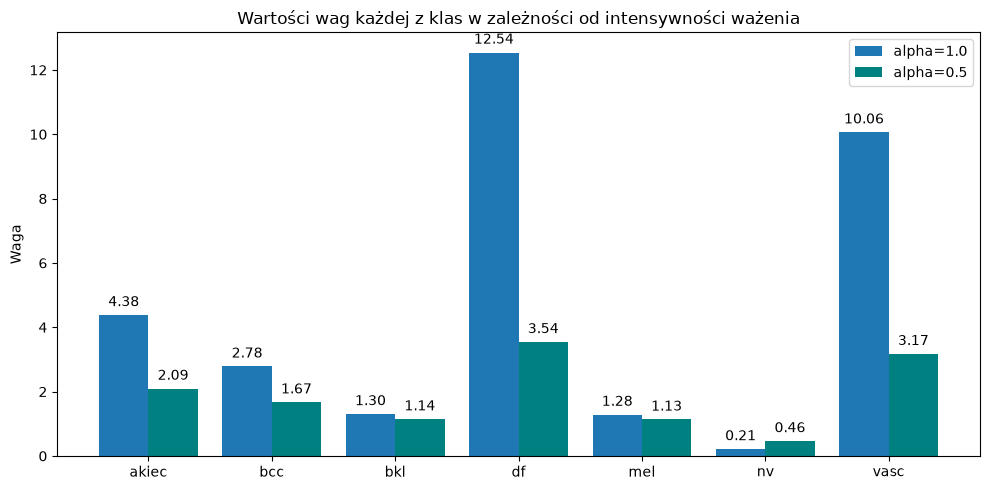

In [12]:
x = np.arange(len(class_names)) 

fig, ax = plt.subplots(figsize=(10, 5))
width=0.40

CW10 = ax.bar(x - width/2, balanced_weights, width, label='alpha=1.0')
CW05 = ax.bar(x + width/2, moderate_balanced_weights.values(), width, label='alpha=0.5', color="teal")

ax.set_ylabel('Waga')
ax.set_title("Wartości wag każdej z klas w zależności od intensywności ważenia")
ax.set_xticks(x)
ax.set_xticklabels(class_names)
ax.legend()

ax.bar_label(CW10, fmt="%.2f", padding=4)
ax.bar_label(CW05, fmt="%.2f", padding=4)

plt.tight_layout()
plt.show()


## 4. Konfiguracja i trening modeli

In [13]:
EXPERIMENTS = {"CW05": 0.5, "CW06": 0.60, "CW07": 0.7, "CW08": 0.8,"CW09": 0.9, "CW10": 1.0}

In [14]:
def build_callbacks(exp_id):
    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(OUT_DIR/ exp_id / 'best.keras'),
            monitor="val_f1_macro",
            mode="max",
            save_best_only=True,
        ),
    
        tf.keras.callbacks.EarlyStopping(
            monitor="val_f1_macro",
            mode="max",
            patience=10,
            min_delta=0.005,
            restore_best_weights=True,
        )
    ]

    return callbacks
    

### 4.1. Trening

In [15]:
def run_experiment(exp_id, alpha):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    
    exp_dir = OUT_DIR / exp_id
    exp_dir.mkdir(parents=True, exist_ok=True)
    model = build_ft3_model(
        BASELINE_PATH,
        (*IMG_SIZE,3),
        model_name=exp_id
    )

    class_weights = build_class_weights(
        alpha=alpha
    )

    history = model.fit(
        train,
        validation_data=val,
        epochs=EPOCHS,
        callbacks=build_callbacks(exp_id),
        class_weight=class_weights
    )

    pd.DataFrame(history.history).to_csv(exp_dir / 'history.csv', index=False)
    
    results = model.evaluate(
        val,
        return_dict=True,
        verbose=0
    )
    
    metrics = {
        "experiment": exp_id,
        "f1_macro": float(results["f1_macro"]),
        "accuracy": float(results["accuracy"]),
        "loss": float(results["loss"])
    }
    
    (exp_dir / "metrics.json").write_text(
        json.dumps(metrics, indent=2),
        encoding="utf-8"
    )
    return metrics

In [16]:
results = [run_experiment(exp_id, alpha) for exp_id, alpha in EXPERIMENTS.items()]

Epoch 1/50


/home/nagorny/miniconda3/envs/tf_gpu_wsl/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1795421929.832888    1020 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_30084__.260
E0000 00:00:1795421930.669294    1020 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


199/201 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.7948 - f1_macro: 0.6910 - loss: 0.5307

I0000 00:00:1795421949.429950    1017 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_30084__.260
E0000 00:00:1795421950.485491    1017 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795421951.102784    1017 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795421952.672406    1017 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795421953.335422    1017 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


201/201 ━━━━━━━━━━━━━━━━━━━━ 43s 136ms/step - accuracy: 0.7948 - f1_macro: 0.6910 - loss: 0.5319 - val_accuracy: 0.7672 - val_f1_macro: 0.6319 - val_loss: 0.6177
Epoch 2/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - accuracy: 0.8043 - f1_macro: 0.6977 - loss: 0.5033 - val_accuracy: 0.7797 - val_f1_macro: 0.6572 - val_loss: 0.5957
Epoch 3/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 0.8181 - f1_macro: 0.7299 - loss: 0.4679 - val_accuracy: 0.7747 - val_f1_macro: 0.6419 - val_loss: 0.6003
Epoch 4/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - accuracy: 0.8279 - f1_macro: 0.7600 - loss: 0.4330 - val_accuracy: 0.7815 - val_f1_macro: 0.6512 - val_loss: 0.5839
Epoch 5/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.8315 - f1_macro: 0.7577 - loss: 0.4312 - val_accuracy: 0.7909 - val_f1_macro: 0.6543 - val_loss: 0.5704
Epoch 6/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.8293 - f1_macro: 0.7623 - loss: 0.4193 - val_accuracy: 0.7803 - val_f1_macro: 0.6530 - 

/home/nagorny/miniconda3/envs/tf_gpu_wsl/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1795422024.401522    1018 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_76699__.260


... (15 outputs left out)

/home/nagorny/miniconda3/envs/tf_gpu_wsl/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1795422519.183802    1017 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_316049__.260


198/201 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.7484 - f1_macro: 0.6290 - loss: 0.6783

I0000 00:00:1795422528.768130    1017 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_316049__.260


201/201 ━━━━━━━━━━━━━━━━━━━━ 29s 88ms/step - accuracy: 0.7485 - f1_macro: 0.6272 - loss: 0.6771 - val_accuracy: 0.7166 - val_f1_macro: 0.5752 - val_loss: 0.7506
Epoch 2/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.7433 - f1_macro: 0.6328 - loss: 0.6147 - val_accuracy: 0.7147 - val_f1_macro: 0.5665 - val_loss: 0.7674
Epoch 3/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - accuracy: 0.7513 - f1_macro: 0.6545 - loss: 0.5528 - val_accuracy: 0.7335 - val_f1_macro: 0.6037 - val_loss: 0.7052
Epoch 4/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.7477 - f1_macro: 0.6462 - loss: 0.5691 - val_accuracy: 0.7222 - val_f1_macro: 0.5790 - val_loss: 0.7481
Epoch 5/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - accuracy: 0.7649 - f1_macro: 0.6667 - loss: 0.5398 - val_accuracy: 0.7335 - val_f1_macro: 0.5912 - val_loss: 0.7033
Epoch 6/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - accuracy: 0.7660 - f1_macro: 0.6797 - loss: 0.5036 - val_accuracy: 0.7341 - val_f1_macro: 0.6047 - v

## 5. Ewaluacja i porównanie wyników

### 5.1. Porównanie metryk F1-macro

In [17]:
results=pd.DataFrame(results)
results["Delta_vs_FT3 (F1_macro)"] = results['f1_macro'] - baseline_F1macro
results

,experiment,f1_macro,accuracy,loss,Delta_vs_FT3 (F1_macro)
0,CW05,0.657164,0.779650,0.595657,-0.024766
1,CW06,0.658182,0.789638,0.571431,-0.023747
2,CW07,0.657595,0.767790,0.608777,-0.024334
3,CW08,0.660187,0.772160,0.608049,-0.021743
4,CW09,0.658383,0.757803,0.636008,-0.023546
5,CW10,0.684724,0.782147,0.627006,0.002795


### 5.2. Porównywanie metryk dla poszczególnych klas dla najlepszego modelu.

In [25]:
models = {
    "FT3": FT3,
    "CW10": tf.keras.models.load_model(
        OUT_DIR / "CW10" / "best.keras"
    )
}

reports = {
    name: evaluate_per_class(model, val, class_names)
    for name, model in models.items()
}

In [26]:
comparison = pd.concat(
    {
        name: report[["precision", "recall", "f1-score"]]
        for name, report in reports.items()
    },
    axis=1
)

display(comparison.round(3))

FT3                      CW10                
      precision recall f1-score precision recall f1-score
akiec     0.735  0.481    0.581     0.659  0.519    0.581
bcc       0.692  0.659    0.675     0.651  0.683    0.667
bkl       0.634  0.580    0.605     0.543  0.682    0.605
df        0.714  0.526    0.606     0.619  0.684    0.650
mel       0.573  0.421    0.485     0.449  0.545    0.492
nv        0.880  0.954    0.916     0.925  0.857    0.890
vasc      0.950  0.864    0.905     0.909  0.909    0.909

In [27]:
delta_cw10 = (
    reports["CW10"][["precision", "recall", "f1-score"]]
    - reports["FT3"][["precision", "recall", "f1-score"]]
)

delta_comparison = pd.concat(
    {
        "CW10 - FT3": delta_cw10
    },
    axis=1
)

display(
    delta_comparison.style
    .format("{:+.3f}")
    .background_gradient(
        cmap="RdBu",
        axis=None,
        vmin=-0.3,
        vmax=0.3
    )
)

### 5.3. Macierze pomyłek

In [28]:
matrixes = {}

for exp_id in EXPERIMENTS:
    cm, disp = build_confusion_matrix(
        model = tf.keras.models.load_model(OUT_DIR / exp_id / 'best.keras'),
        dataset= val,
        class_names=class_names
    )
    matrixes[str(exp_id)] = (cm, disp)

cm_ft3, disp_ft3 = build_confusion_matrix(FT3, val, class_names)

51/51 ━━━━━━━━━━━━━━━━━━━━ 7s 78ms/step
51/51 ━━━━━━━━━━━━━━━━━━━━ 7s 79ms/step
51/51 ━━━━━━━━━━━━━━━━━━━━ 7s 78ms/step
51/51 ━━━━━━━━━━━━━━━━━━━━ 8s 94ms/step
51/51 ━━━━━━━━━━━━━━━━━━━━ 6s 64ms/step
51/51 ━━━━━━━━━━━━━━━━━━━━ 7s 79ms/step
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step


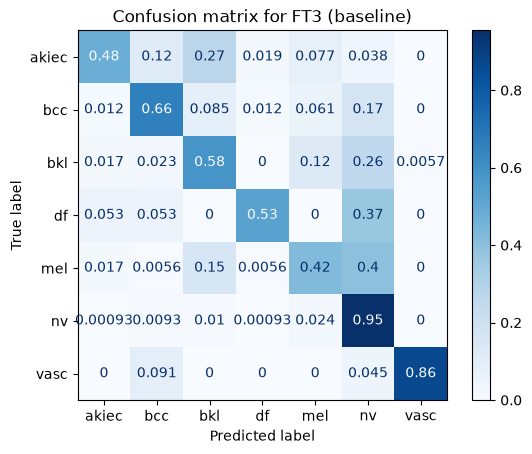

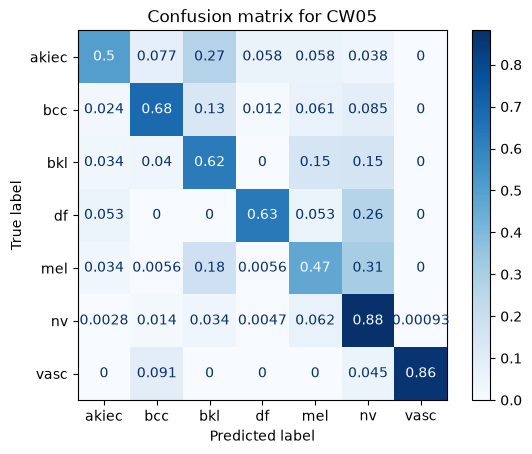

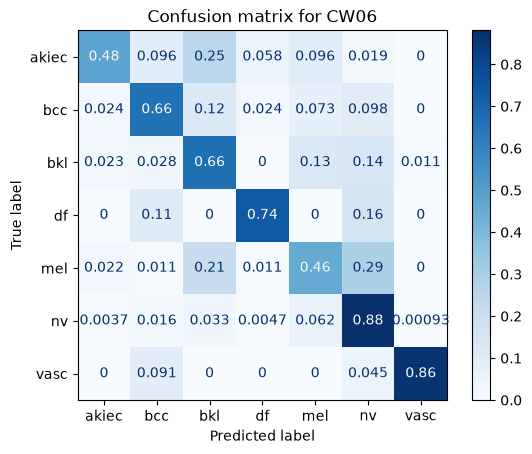

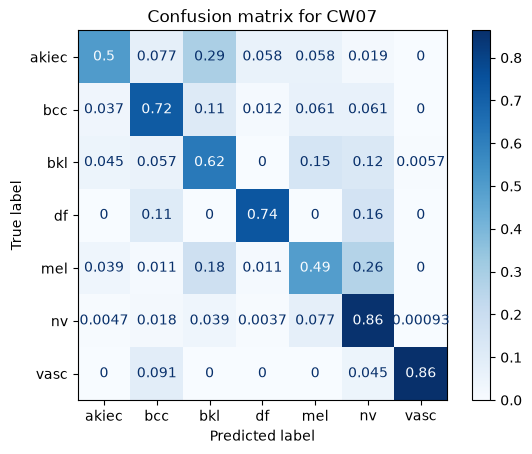

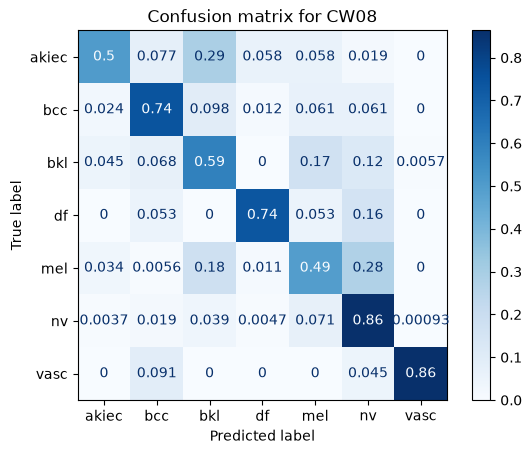

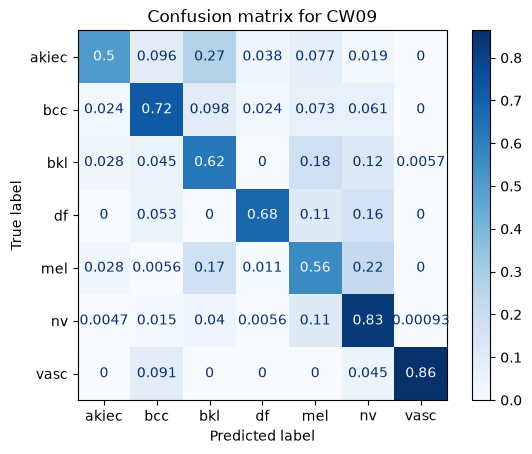

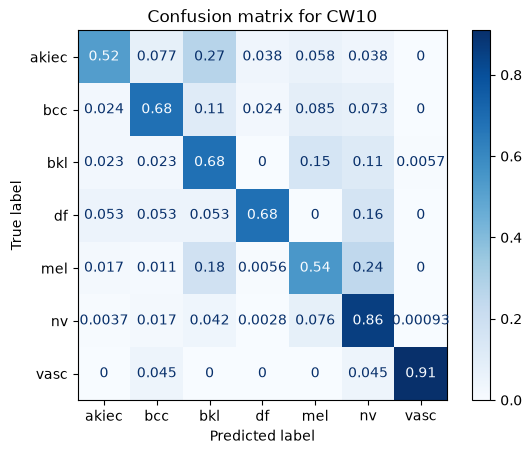

In [22]:
disp_ft3.plot(cmap="Blues")
plt.title("Confusion matrix for FT3 (baseline)")
for exp_id in EXPERIMENTS:
    _ , disp = matrixes[exp_id]
    disp.plot(cmap='Blues')
    plt.title(f"Confusion matrix for {exp_id}")

plt.show()

### 5.4. Macierze pomyłek względem FT3

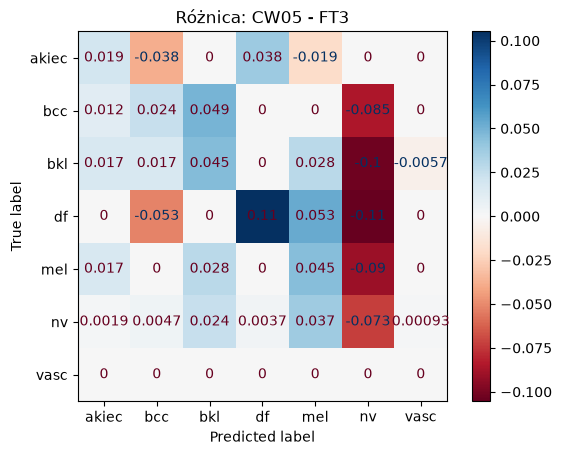

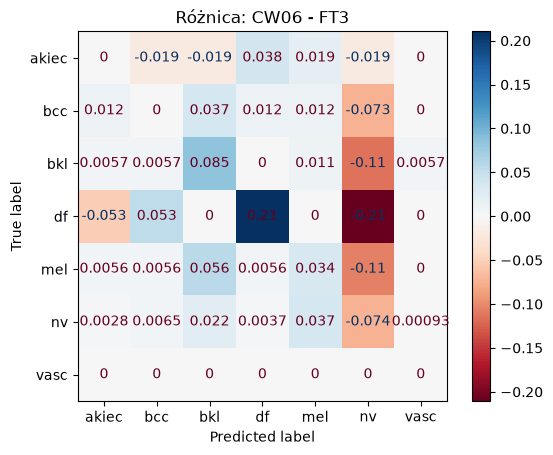

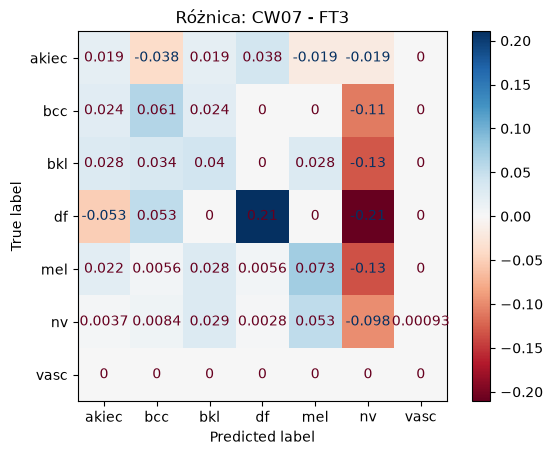

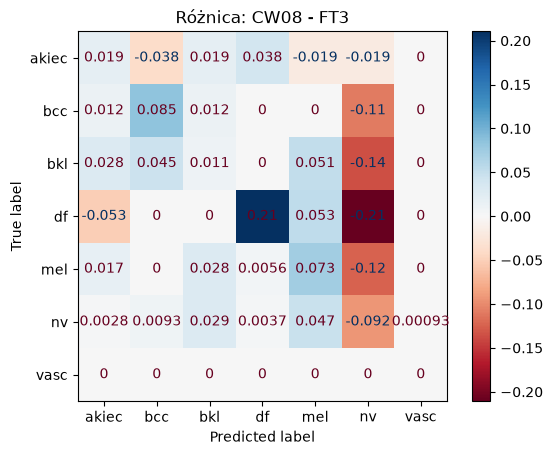

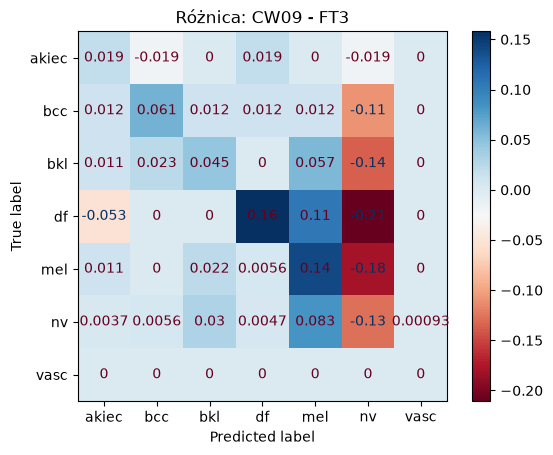

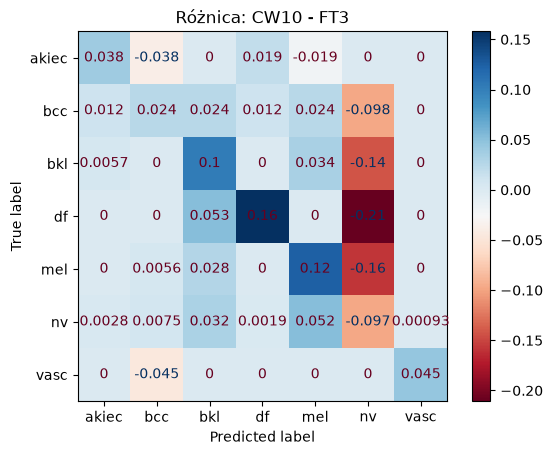

In [23]:
for exp_id in EXPERIMENTS:
    cm , _ = matrixes[exp_id]
    cm_diff = cm - cm_ft3
    disp = ConfusionMatrixDisplay(cm_diff, display_labels=class_names)
    disp.plot(cmap="RdBu")
    plt.title(f"Różnica: {exp_id} - FT3")

plt.show()

### 5.5. Krzywe uczenia

EKSPERYMENT CW05


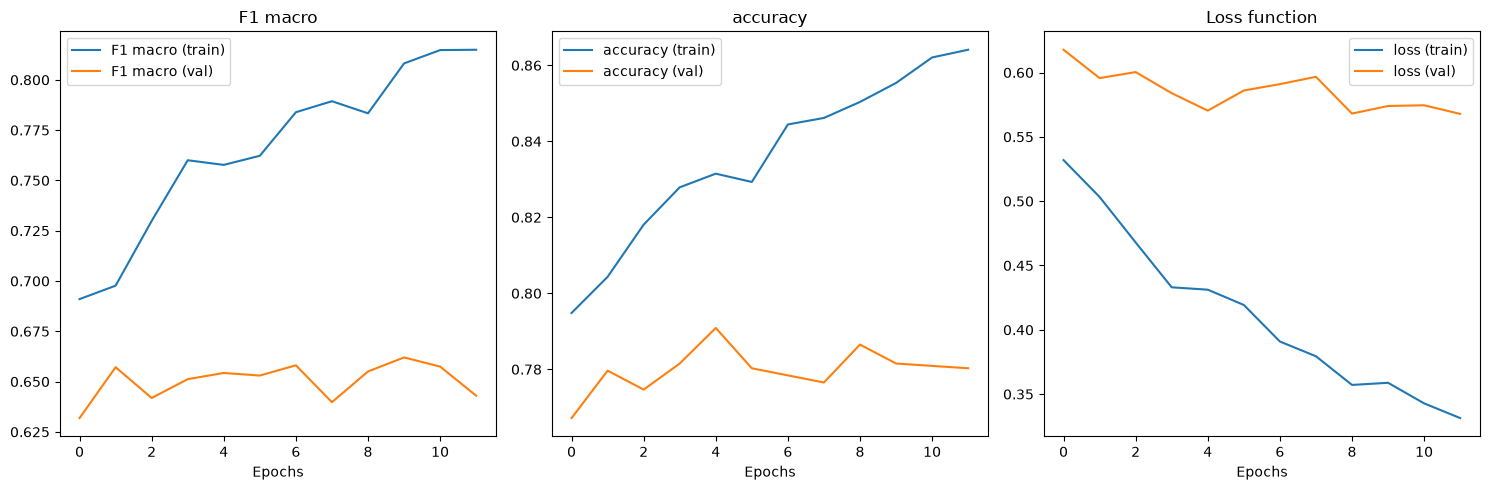

EKSPERYMENT CW06


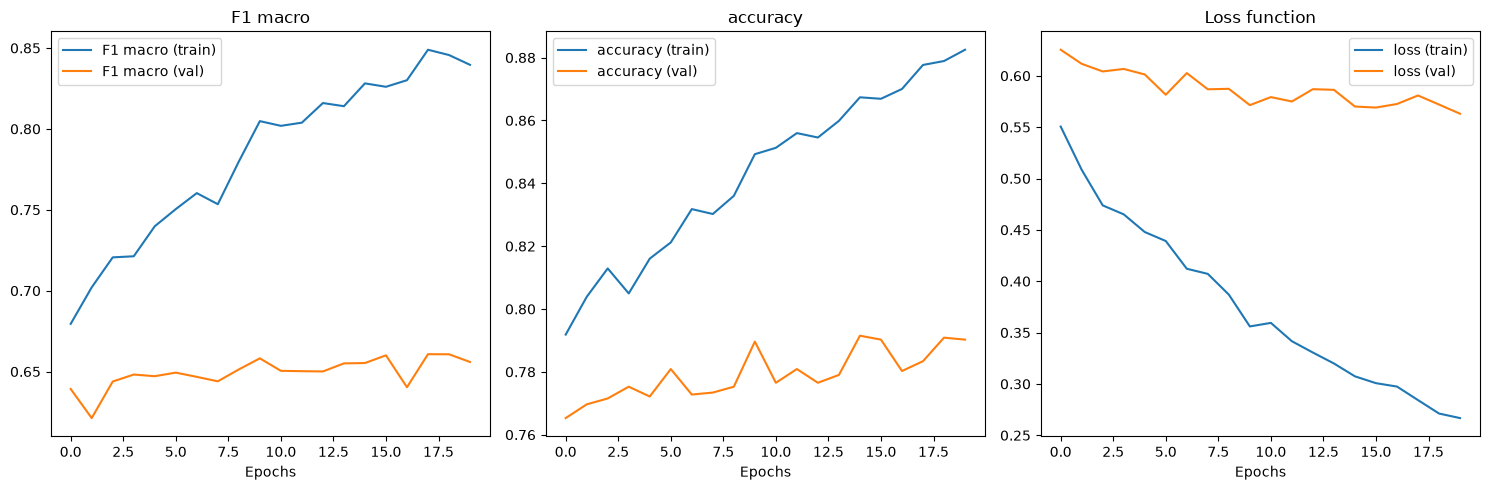

EKSPERYMENT CW07


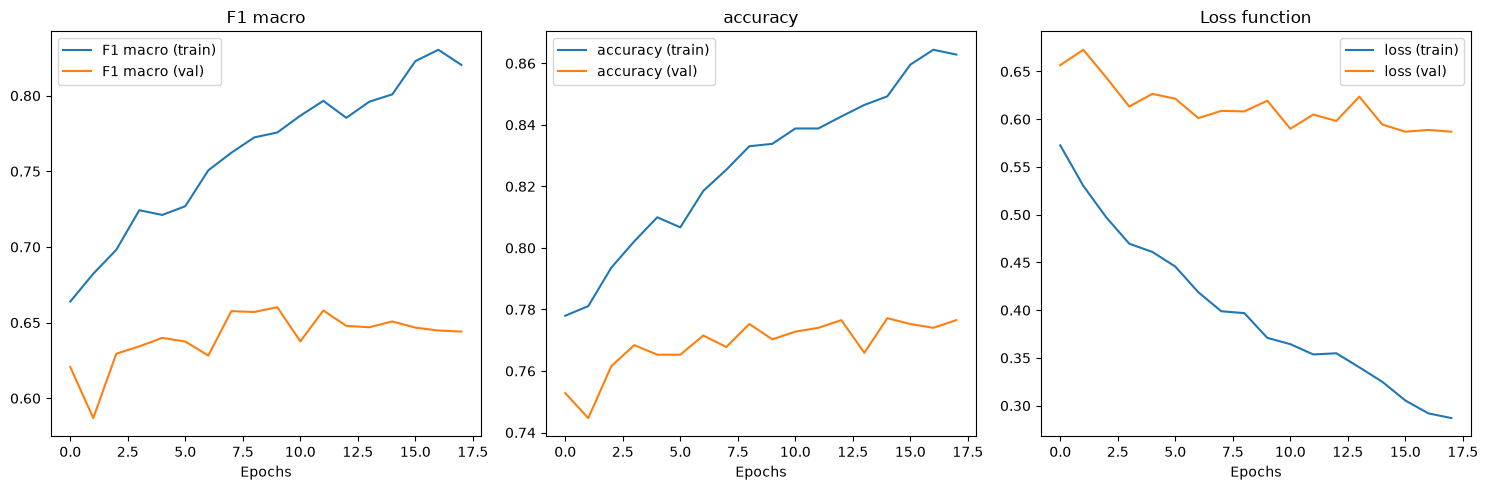

EKSPERYMENT CW08


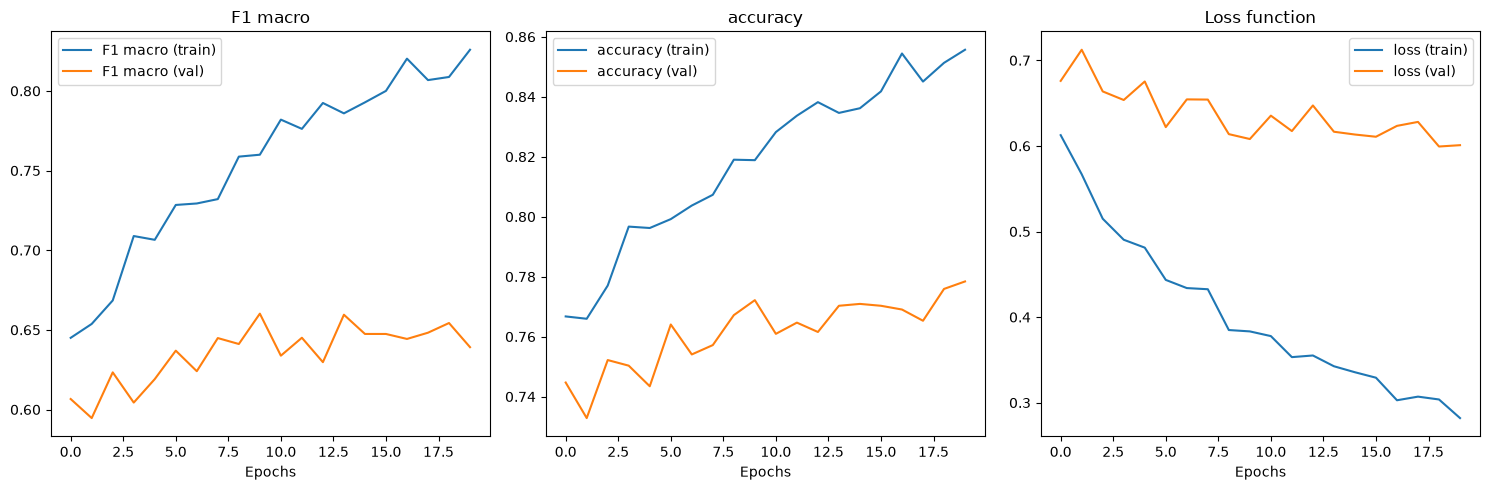

EKSPERYMENT CW09


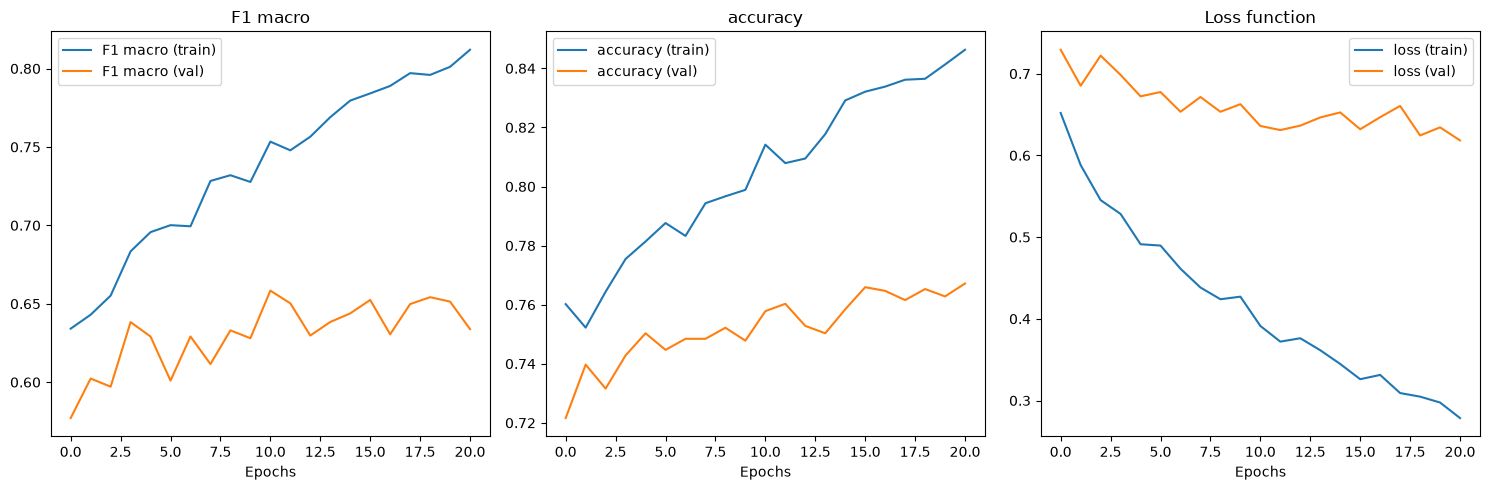

EKSPERYMENT CW10


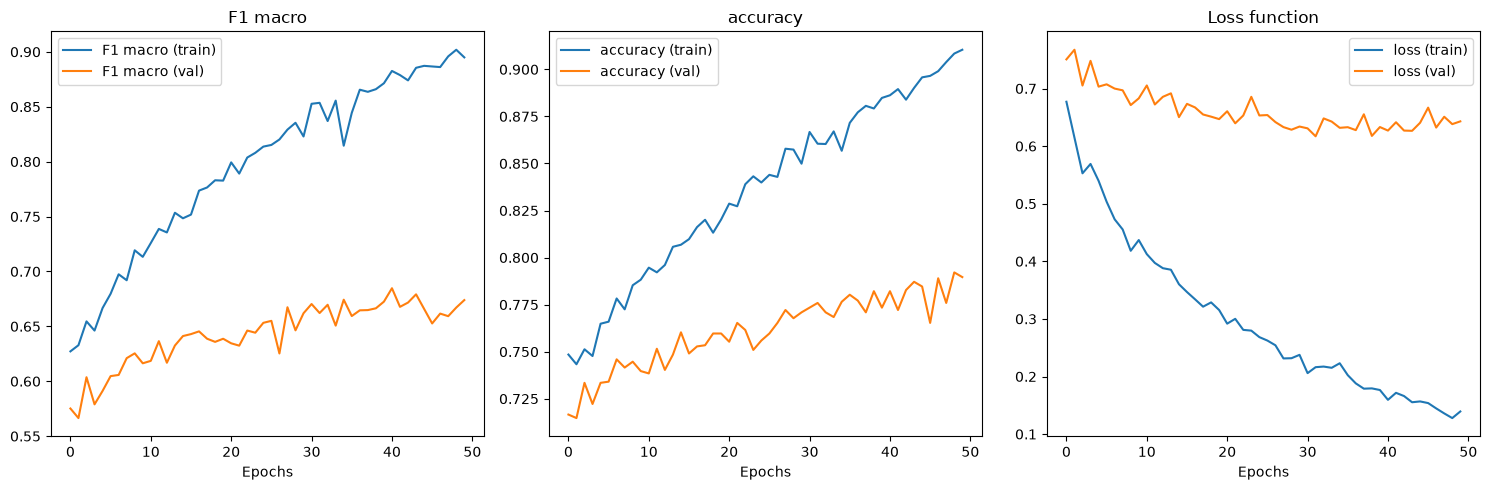

In [24]:
for exp_id in EXPERIMENTS:
    print(f"EKSPERYMENT {exp_id}")
    hist= pd.read_csv(OUT_DIR / exp_id / 'history.csv')
    history_plot(hist)

## 6. Wnioski i wybór konfiguracji.

- Zastosowanie ważenia klas istotnie zmniejsza bias związany z dysbalansem danych, co widać m.in. na przekątnej macierzy pomyłek. Model zmienił rodzaj popełnianych błędów, nie faworyzując już najliczniejszej z klas.

-  Zastosowanie pełnego ważenia klas nie poprawiło ogólnej skuteczności modelu niezależnie od wartości $\alpha$— wartość F1-macro spadła o około 0.02 względem modelu referencyjnego FT3 dla większości wariantów, natomiast dla pełnego ważenia osiągnął on wynik porównywalny z FT3 $F1_{macro}=0.6847$.

- Ważenie klas ograniczyło tendencję modelu do przypisywania próbek klas mniejszościowych do dominującej klasy `nv`. Szczególnie wyraźnie zmniejszyła się liczba pomyłek `mel -> nv` (−0,16), `df -> nv` (−0,21) oraz `bkl -> nv` (−0,10) dla pełnego ważenia klas.

- Największą poprawę F1-macro zaobserwowano przy pełnym ważeniu. Odnotowano poprawę recall trzech klas: `df` (+0,16), `mel` (+0,12) oraz `bkl` (+0,1). Recall klas `akiec` i `vasc` pozostał bez większych zmian zmian.

- Poprawa rozpoznawania klas mniejszościowych odbyła się jednak kosztem skuteczności klasyfikacji `nv`, której recall spadł o w każdej z konfiguracji. Jednocześnie wzrosła liczba błędnych predykcji `mel` dla rzeczywistych przypadków `nv`.

- Spadek F1-macro pomimo poprawy recall części klas sugeruje, że korzyści z ograniczenia pominięć zostały zniwelowane przez pogorszenie innych aspektów klasyfikacji, w tym spadek precision.

Następnym krokiem będzie powrót do poprzedniego etapu eksperymentów z augmentacją danych, poszerzając eksperymenty o pełne ważenie klas.

